# Gaussian-Linear Hidden Markov Model

This notebook shows an example of training and inspecting a Gaussian-Linear Hidden Markov Model (GLHMM). This model is fit to two sets of timeseries, such as a neuroimaging/electrophysiological recording and a corresponding behavioural or other physiological timeseries.

# Example: Modelling time-varying interaction between brain and physiological data

We will now go through an example illustrating how to fit and inspect a GLHMM. The example uses simulated data that can be found in the example_data folder. The data were generated to resemble one set of fMRI timeseries and two corresponding non-brain physiological (e.g., heart rate and respiration) timeseries.

**Our goal is to estimate time-varying amplitude and functional connectivity (FC) within the fMRI recordings and temporal changes in the relationship between the fMRI and the physiological data.**

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sb
from glhmm import glhmm, preproc, utils, graphics

In [2]:
brain_data = pd.read_csv('./GLHMM-example-data/data.csv', header=None).to_numpy()
phys_data = pd.read_csv('./GLHMM-example-data/dataX.csv', header=None).to_numpy()
T_t = pd.read_csv('./GLHMM-example-data/T.csv', header=None).to_numpy()

In [3]:
brain_data.shape, phys_data.shape, T_t.shape 

((20000, 50), (20000, 2), (20, 2))

NOTE: It is important to standardise your timeseries and, if necessary, apply other kinds of preprocessing before fitting the model.

In [4]:
brain_data,_,preproclogY = preproc.preprocess_data(brain_data, T_t)
phys_data,_,preproclogX = preproc.preprocess_data(phys_data, T_t)

# Initialise and train a GLHMM

There are two options for modelling the interaction: global, meaning we estimate regression coefficients that are static over the timeseries in which case model_beta='shared', or state-dependent, meaning we estimate regression coefficients that vary over time in which case model_beta='state'. In this example, we want to model the time-varying interaction between the brain data and the physiological data, so we set model_beta='state'

In [5]:
brainphys_glhmm = glhmm.glhmm(model_beta='state', K=4, covtype='full', preproclogX=preproclogX, preproclogY=preproclogY)
print(brainphys_glhmm.hyperparameters)

{'K': 4, 'covtype': 'full', 'model_mean': 'state', 'model_beta': 'state', 'dirichlet_diag': 10, 'connectivity': None, 'Pstructure': array([[ True,  True,  True,  True],
       [ True,  True,  True,  True],
       [ True,  True,  True,  True],
       [ True,  True,  True,  True]]), 'Pistructure': array([ True,  True,  True,  True])}


In [ ]:
# train data
np.random.seed(123)
brainphys_glhmm.train(X=phys_data, Y=brain_data, indices=T_t)

Init repetition 1 free energy = 1380547.7682795075
Init repetition 2 free energy = 1381382.5994832248
Init repetition 3 free energy = 1380931.5982499316
Init repetition 4 free energy = 1382061.7363274982
Init repetition 5 free energy = 1381593.5630846655
Best repetition: 1
Cycle 1 free energy = 1380566.7604436672
Cycle 2 free energy = 1379862.1648943217
Cycle 3, free energy = 1379551.346207098, relative change = 0.30610038349846547
Cycle 4, free energy = 1379275.1572224665, relative change = 0.21383423337611604
Cycle 5, free energy = 1379028.2265415532, relative change = 0.1604973933782607
Cycle 6, free energy = 1378789.265018783, relative change = 0.1344372083465083
Cycle 7, free energy = 1378592.5734466284, relative change = 0.09963168253547958
Cycle 8, free energy = 1378427.6619013124, relative change = 0.07709394497293792
Cycle 9, free energy = 1378277.325776013, relative change = 0.0656651737755759
Cycle 10, free energy = 1378143.2996386515, relative change = 0.055303612537967554


(array([[3.75610701e-03, 2.94092117e-01, 6.98383755e-01, 3.76802101e-03],
        [1.44129925e-03, 1.55704532e-01, 8.42585195e-01, 2.68973480e-04],
        [3.01355467e-05, 3.37633937e-03, 9.96541428e-01, 5.20972369e-05],
        ...,
        [9.47547227e-07, 1.36571930e-02, 9.01553473e-01, 8.47883869e-02],
        [3.02682822e-07, 4.55442819e-04, 9.99378071e-01, 1.66183614e-04],
        [1.30822026e-05, 2.92804710e-05, 9.99933710e-01, 2.39276683e-05]],
       shape=(20000, 4)),
 array([[[4.89027300e-04, 1.42293165e-04, 3.12459123e-03, 1.95313845e-07],
         [8.49760599e-04, 1.54962398e-01, 1.38163743e-01, 1.16215276e-04],
         [9.88740132e-05, 4.60829566e-04, 6.97793890e-01, 3.01622162e-05],
         [3.63734100e-06, 1.39011715e-04, 3.50297128e-03, 1.22400674e-04]],
 
        [[5.28327223e-06, 1.28682071e-06, 1.43470229e-03, 2.68680262e-08],
         [2.20367397e-05, 3.36388544e-03, 1.52280235e-01, 3.83748613e-05],
         [2.80903665e-06, 1.09592213e-05, 8.42560515e-01, 1.091

# Inspect model

**Interaction between brain and physiological measures**

Let’s start by retrieving the parameters describing the interaction, i.e., the Beta 
 values, between the two sets of timeseries: the brain data and the physiological data (heart rate & respiration). 

In [7]:
K = brainphys_glhmm.hyperparameters["K"] # the number of states
q = brain_data.shape[1] # the number of parcels/channels
state_betas = np.zeros(shape=(2,q,K))
state_betas = brainphys_glhmm.get_betas()

Since we here defined Beta to be time-varying, i.e., state-dependent, we have a matrix describing the interaction between each of the 50 brain regions and the 2 physiological measures for each of the 4 states:



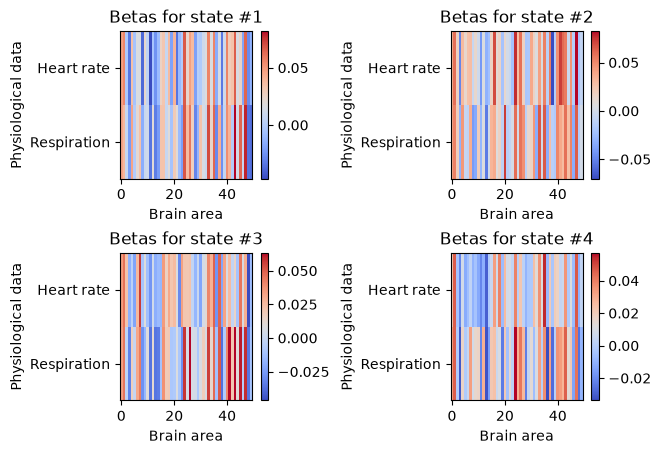

In [8]:
cmap = "coolwarm"
ytick =["Heart rate", "Respiration"]
for k in range(K):
    plt.subplot(2,2,k+1)
    plt.imshow(state_betas[:,:,k], cmap=cmap,aspect='auto', interpolation='none')
    plt.colorbar()
    plt.ylabel('Physiological data')
    plt.yticks(np.arange(2), ytick)
    plt.xlabel('Brain area')
    plt.title(f"Betas for state #{k+1}")
plt.subplots_adjust(hspace=0.5, wspace=1)
plt.show()


# State means and covariances

We have defined the model so that each state also has a mean (amplitude) and covariance (functional connectivity)

In [9]:
state_means = np.zeros(shape=(q, K))
for k in range(K):
    state_means[:,k] = brainphys_glhmm.get_mean(k) # the state means in the shape (no. features, no. states)
state_FC = np.zeros(shape=(q, q, K))
for k in range(K):
    state_FC[:,:,k] = brainphys_glhmm.get_covariance_matrix(k=k) # the state covariance matrices in the shape (no. features, no. features, no. states)

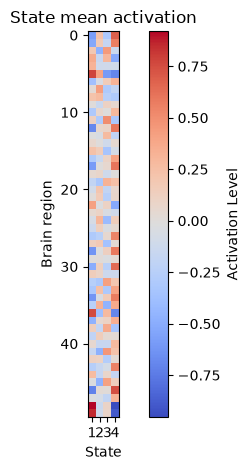

In [10]:
plt.imshow(state_means,cmap=cmap, interpolation="none")
plt.colorbar(label='Activation Level') # Label for color bar
plt.title("State mean activation")
plt.xticks(np.arange(K), np.arange(1,K+1))
plt.gca().set_xlabel('State')
plt.gca().set_ylabel('Brain region')
plt.tight_layout()  # Adjust layout for better spacing
plt.show()

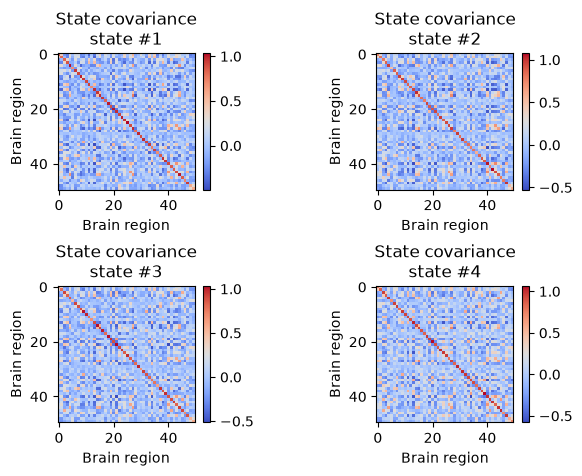

In [11]:
for k in range(K):
    plt.subplot(2,2,k+1)
    plt.imshow(state_FC[:,:,k], cmap=cmap, interpolation="none")
    plt.xlabel('Brain region')
    plt.ylabel('Brain region')
    plt.colorbar()
    plt.title("State covariance\nstate #%s" % (k+1))
plt.subplots_adjust(hspace=0.7, wspace=0.8)
plt.show()

# Dynamics: Transition probabilities and Viterbi path

The transition probabilities indicate the temporal order in the state sequence, i.e., the probability of transitioning from any one state to any other state.

The Viterbi path is a discrete representation of the state timecourse, indicating which state is active at which timepoint. 

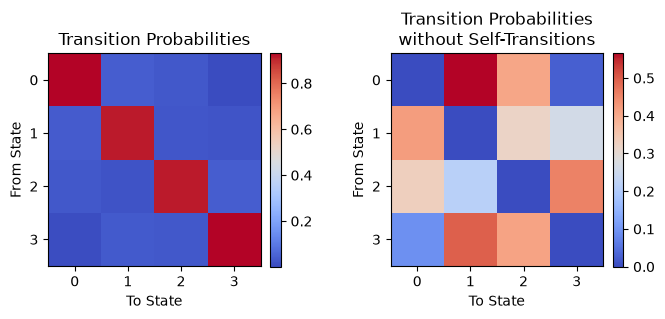

In [12]:
TP = brainphys_glhmm.P.copy() # the transition probability matrix

# Plot Transition Probabilities
plt.figure(figsize=(7, 4))

# Plot 1: Full Transition Probabilities
plt.subplot(1, 2, 1)
plt.imshow(TP, cmap=cmap, interpolation='nearest')  # Improved color mapping
plt.title('Transition Probabilities')
plt.xlabel('To State')
plt.ylabel('From State')
plt.colorbar(fraction=0.046, pad=0.04)

# Plot 2: Transition Probabilities without Self-Transitions
TP_noself = TP - np.diag(np.diag(TP))  # Remove self-transitions
TP_noself2 = TP_noself / TP_noself.sum(axis=1, keepdims=True)  # Normalize probabilities
plt.subplot(1, 2, 2)
plt.imshow(TP_noself2, cmap=cmap, interpolation='nearest')  # Improved color mapping
plt.title('Transition Probabilities\nwithout Self-Transitions')
plt.xlabel('To State')
plt.ylabel('From State')
plt.colorbar(fraction=0.046, pad=0.04)

plt.tight_layout()  # Adjust layout for better spacing
plt.show()

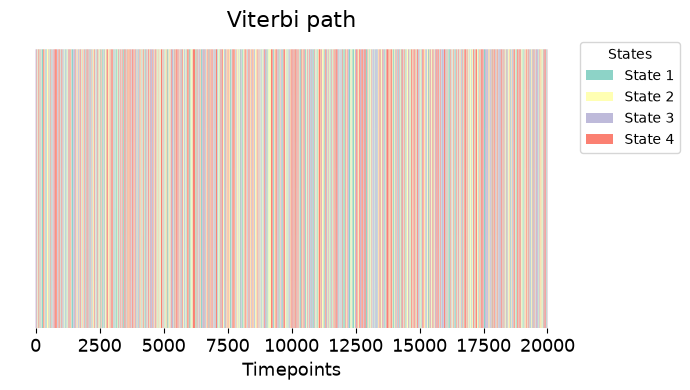

In [13]:
vpath = brainphys_glhmm.decode(X=phys_data, Y=brain_data, indices=T_t, viterbi=True)
graphics.plot_vpath(vpath, title="Viterbi path")

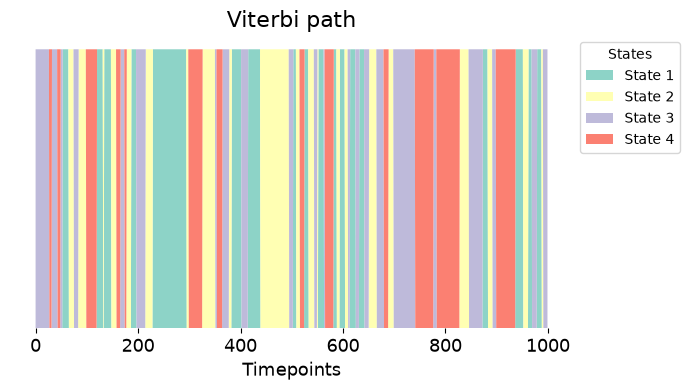

In [14]:
num_subject = 0
graphics.plot_vpath(vpath[T_t[num_subject,0]:T_t[num_subject,1],:], title="Viterbi path")